# TP Kafka : meteo en temps reel

## Exercice 1 : topic et producteur simple

1. Creer le topic `weather_stream`.
2. Envoyer un message statique `{"msg": "Hello Kafka"}`.

In [4]:
from kafka.admin import KafkaAdminClient, NewTopic

admin = KafkaAdminClient(bootstrap_servers="kafka:9092")
if "weather_stream" not in admin.list_topics():
    admin.create_topics([NewTopic("weather_stream", 1, 1)])
print(admin.list_topics())

['weather_stream']


In [5]:
from kafka import KafkaProducer

producer = KafkaProducer(bootstrap_servers="kafka:9092")

meta = producer.send("weather_stream", b'{"msg": "Hello Kafka"}').get(timeout=10)
print(f"envoye -> partition {meta.partition}, offset {meta.offset}")

envoye -> partition 0, offset 2


## Exercice 3 : streaming Open-Meteo

`exo3.py` interroge l'API Open-Meteo toutes les 30 s pour les 5 villes et envoie chaque reponse + `city`/`country` dans `weather_stream`. Daemon : `docker exec -d pyspark_notebook python work/exo3.py`

Preuve : `exo2.py` lit le flux en direct — les 5 villes defilent avec `temperature_2m`, `wind_speed_10m`, `weather_code`.

## Exercice 4 : transformation Spark et alertes

Lit `weather_stream` en continu, calcule `wind_alert_level` et `heat_alert_level`, ecrit dans `weather_transformed`.

- vent : < 10 m/s `level_0` - 10-20 `level_1` - > 20 `level_2`
- chaleur : < 25 C `level_0` - 25-35 `level_1` - > 35 `level_2`
- `event_time` = timestamp d'ecriture du message dans Kafka (colonne `timestamp` de la source)

In [9]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import types as T

spark = (SparkSession.builder
         .appName("weather-transform")
         .master("spark://spark-master:7077")
         .getOrCreate())

schema = T.StructType([
    T.StructField("city", T.StringType()),
    T.StructField("country", T.StringType()),
    T.StructField("current", T.StructType([
        T.StructField("temperature_2m", T.DoubleType()),
        T.StructField("wind_speed_10m", T.DoubleType()),
        T.StructField("weather_code", T.IntegerType()),
    ])),
])

brut = (spark.readStream.format("kafka")
    .option("kafka.bootstrap.servers", "kafka:9092")
    .option("subscribe", "weather_stream")
    .option("startingOffsets", "earliest")
    .load())

In [10]:
meteo = (brut
    .select(F.from_json(F.col("value").cast("string"), schema).alias("d"),
            F.col("timestamp").alias("event_time"))
    .select("event_time", "d.*")
    .filter(F.col("city").isNotNull())   # ecarte les messages hors schema (Hello Kafka)
    .select("event_time",
            F.col("current.temperature_2m").alias("temperature"),
            F.col("current.wind_speed_10m").alias("windspeed"),
            "city", "country",
            F.col("current.weather_code").alias("weather_code"))
    .withColumn("wind_alert_level",
        F.when(F.col("windspeed") < 10, "level_0")
         .when(F.col("windspeed") <= 20, "level_1")
         .otherwise("level_2"))
    .withColumn("heat_alert_level",
        F.when(F.col("temperature") < 25, "level_0")
         .when(F.col("temperature") <= 35, "level_1")
         .otherwise("level_2")))

requete = (meteo.select(F.to_json(F.struct("*")).alias("value"))
    .writeStream.format("kafka")
    .option("kafka.bootstrap.servers", "kafka:9092")
    .option("topic", "weather_transformed")
    .option("checkpointLocation", "/home/jovyan/work/checkpoints/exo4")
    .outputMode("append")
    .start())
print(requete.status)

{'message': 'Initializing sources', 'isDataAvailable': False, 'isTriggerActive': False}


Verification : on relit `weather_transformed` comme un consommateur classique (5 messages).

In [11]:
import json
from kafka import KafkaConsumer

consumer = KafkaConsumer("weather_transformed", bootstrap_servers="kafka:9092",
    auto_offset_reset="earliest",
    value_deserializer=lambda b: json.loads(b.decode()),
    consumer_timeout_ms=60000)
for i, m in enumerate(consumer):
    print(m.value)
    if i >= 4: break

{'event_time': '2026-11-10T13:27:08.759Z', 'temperature': 12.1, 'windspeed': 2.08, 'city': 'Paris', 'country': 'France', 'weather_code': 80, 'wind_alert_level': 'level_0', 'heat_alert_level': 'level_0'}
{'event_time': '2026-11-10T13:27:08.935Z', 'temperature': 21.4, 'windspeed': 5.82, 'city': 'Seville', 'country': 'Spain', 'weather_code': 80, 'wind_alert_level': 'level_0', 'heat_alert_level': 'level_0'}
{'event_time': '2026-11-10T13:27:09.118Z', 'temperature': 30.6, 'windspeed': 3.62, 'city': 'Dubai', 'country': 'United Arab Emirates', 'weather_code': 0, 'wind_alert_level': 'level_0', 'heat_alert_level': 'level_1'}
{'event_time': '2026-11-10T13:27:09.297Z', 'temperature': 6.7, 'windspeed': 6.8, 'city': 'Reykjavik', 'country': 'Iceland', 'weather_code': 3, 'wind_alert_level': 'level_0', 'heat_alert_level': 'level_0'}
{'event_time': '2026-11-10T13:27:09.488Z', 'temperature': 15.5, 'windspeed': 7.44, 'city': 'Wellington', 'country': 'New Zealand', 'weather_code': 51, 'wind_alert_level': '

## Exercice 5 : agregats en fenetre glissante

Lit `weather_transformed`, fenetre de **1 minute glissant toutes les 30 s** sur `event_time`, watermark 1 min.
Par fenetre et par ville : alertes vent L1/L2, alertes chaleur L1/L2, total d'alertes, moyenne/min/max de la temperature.

Sortie `console` en mode `update` : le driver ecrit dans stdout du conteneur -> visible avec `docker logs -f pyspark_notebook` (depuis Windows).

In [15]:
schema_t = T.StructType([
    T.StructField("event_time", T.TimestampType()),
    T.StructField("temperature", T.DoubleType()),
    T.StructField("windspeed", T.DoubleType()),
    T.StructField("city", T.StringType()),
    T.StructField("country", T.StringType()),
    T.StructField("weather_code", T.IntegerType()),
    T.StructField("wind_alert_level", T.StringType()),
    T.StructField("heat_alert_level", T.StringType()),
])

meteo_t = (spark.readStream.format("kafka")
    .option("kafka.bootstrap.servers", "kafka:9092")
    .option("subscribe", "weather_transformed")
    .option("startingOffsets", "earliest")
    .load()
    .select(F.from_json(F.col("value").cast("string"), schema_t).alias("d"))
    .select("d.*"))

In [16]:
agg = (meteo_t
    .withWatermark("event_time", "1 minute")
    .groupBy(F.window("event_time", "1 minute", "30 seconds"), "country", "city")
    .agg(
        F.sum(F.when(F.col("wind_alert_level") == "level_1", 1).otherwise(0)).alias("alertes_vent_1"),
        F.sum(F.when(F.col("wind_alert_level") == "level_2", 1).otherwise(0)).alias("alertes_vent_2"),
        F.sum(F.when(F.col("heat_alert_level") == "level_1", 1).otherwise(0)).alias("alertes_chaleur_1"),
        F.sum(F.when(F.col("heat_alert_level") == "level_2", 1).otherwise(0)).alias("alertes_chaleur_2"),
        F.sum(F.when(F.col("wind_alert_level") != "level_0", 1).otherwise(0)
            + F.when(F.col("heat_alert_level") != "level_0", 1).otherwise(0)).alias("total_alertes"),
        F.round(F.avg("temperature"), 1).alias("temp_moy"),
        F.min("temperature").alias("temp_min"),
        F.max("temperature").alias("temp_max")))

requete5 = (agg.writeStream.format("console")
    .outputMode("update")
    .option("truncate", False)
    .option("checkpointLocation", "/home/jovyan/work/checkpoints/exo5")
    .start())
print(requete5.status)

{'message': 'Initializing sources', 'isDataAvailable': False, 'isTriggerActive': False}


## Exercice 6 : stockage HDFS

`exo6.py` consomme `weather_transformed` en continu et ajoute chaque message en une ligne JSON dans `/hdfs-data/{country}/{city}/alerts.json` (append-only, jamais reecrit — tous les messages gardes, `level_0` compris, pour l'exercice 7).

Ecriture via le client HDFS natif (`FileSystem.append` en RPC `hdfs://namenode:9000`, session Spark `local[1]`) : l'append WebHDFS est casse sur ce cluster mono-datanode (pipeline replacement impossible).

Daemon : `docker exec -d pyspark_notebook python work/exo6.py`

Verification depuis le notebook (lecture WebHDFS) : tailles des fichiers par ville — relancer la cellule pour les voir grandir.

In [ ]:
from hdfs import InsecureClient

h = InsecureClient("http://namenode:9870", user="root")
for pays in h.list("/hdfs-data"):
    for ville in h.list(f"/hdfs-data/{pays}"):
        p = f"/hdfs-data/{pays}/{ville}/alerts.json"
        print(f"{p}  ->  {h.status(p)['length']} octets")

## Exercice 7 : analyse des logs HDFS

Lecture des `alerts.json` accumules par l'exercice 6 (`spark.read.json` sur `hdfs://namenode:9000/hdfs-data/*/*/`), puis 4 sorties :

1. evolution de la temperature au fil du temps
2. evolution de la vitesse du vent au fil du temps
3. nombre d'alertes vent et chaleur par niveau
4. code meteo le plus frequent par pays

Nettoyage a la lecture : les logs contiennent quelques lignes en double (relecture de l'historique par le consumer) et parfois des reponses API sans donnees meteo (champs `null` -> alertes `level_2` factices) ; ils sont filtres dans la cellule suivante.

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

logs = spark.read.schema(schema_t).json("hdfs://namenode:9000/hdfs-data/*/*/alerts.json")
print(logs.count(), "messages")

df = (logs.toPandas()
      .drop_duplicates()                  # doublons du rattrapage du consumer
      .dropna(subset=["temperature"]))    # reponses API sans donnees -> level_2 factices
df["event_time"] = pd.to_datetime(df["event_time"])
df = df.sort_values("event_time")
df.head()

1552 messages


,event_time,temperature,windspeed,city,country,weather_code,wind_alert_level,heat_alert_level
1241,2026-11-10 13:27:08.759,12.1,2.08,Paris,France,80.0,level_0,level_0
930,2026-11-10 13:27:08.935,21.4,5.82,Seville,Spain,80.0,level_0,level_0
0,2026-11-10 13:27:09.118,30.6,3.62,Dubai,United Arab Emirates,0.0,level_0,level_1
620,2026-11-10 13:27:09.297,6.7,6.80,Reykjavik,Iceland,3.0,level_0,level_0
310,2026-11-10 13:27:09.488,15.5,7.44,Wellington,New Zealand,51.0,level_0,level_0


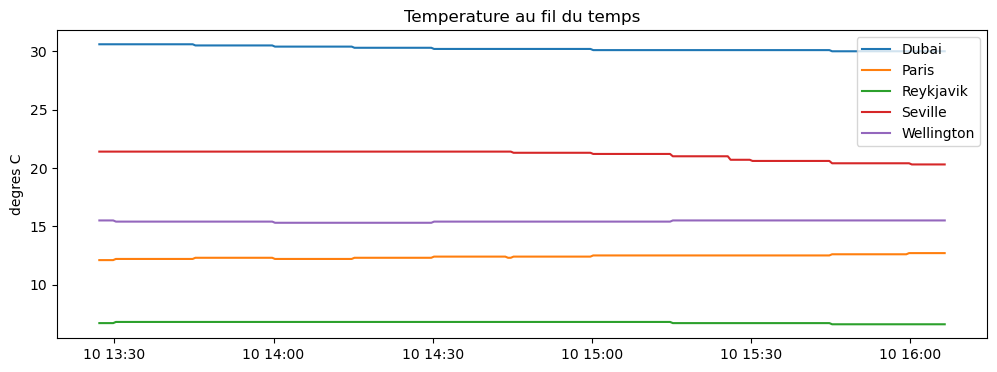

In [31]:
# 1. Evolution de la temperature par ville
fig, ax = plt.subplots(figsize=(12, 4))
for ville, g in df.groupby("city"):
    ax.plot(g["event_time"], g["temperature"], label=ville)
ax.set_title("Temperature au fil du temps"); ax.set_ylabel("degres C")
ax.legend(); plt.show()

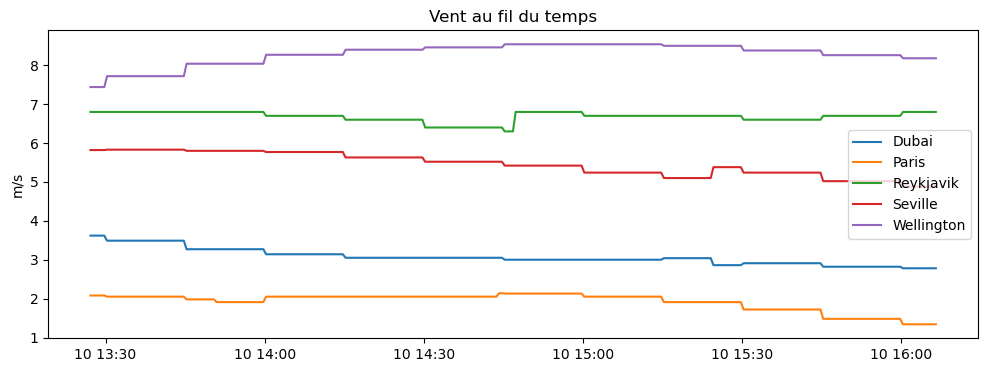

In [32]:
# 2. Evolution de la vitesse du vent par ville
fig, ax = plt.subplots(figsize=(12, 4))
for ville, g in df.groupby("city"):
    ax.plot(g["event_time"], g["windspeed"], label=ville)
ax.set_title("Vent au fil du temps"); ax.set_ylabel("m/s")
ax.legend(); plt.show()

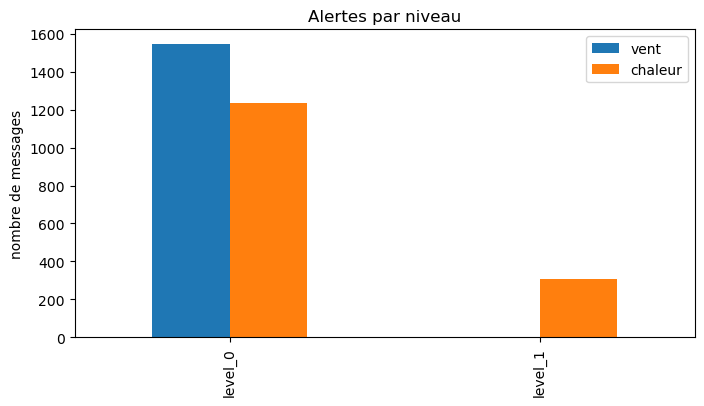

,vent,chaleur
level_0,1545,1236
level_1,0,309


In [33]:
# 3. Nombre d'alertes par niveau (vent et chaleur)
alertes = pd.concat([
    df["wind_alert_level"].value_counts().rename("vent"),
    df["heat_alert_level"].value_counts().rename("chaleur"),
], axis=1).fillna(0).astype(int)
alertes.plot.bar(figsize=(8, 4), title="Alertes par niveau")
plt.ylabel("nombre de messages"); plt.show()
alertes

In [34]:
# 4. Code meteo le plus frequent par pays (codes WMO)
df.groupby("country")["weather_code"].agg(lambda s: s.mode().iat[0])

country
France                   3.0
Iceland                  3.0
New Zealand             51.0
Spain                   80.0
United Arab Emirates     0.0
Name: weather_code, dtype: float64